# От данных к материалам тьютора: результат

Предварительное описательное исследование, 4 ноября 2026. Только сохранённые 100 разборов; основные частоты по 98. Новых решений, аудитов, ответов учеников и изменений каталога нет.

[Открыть картинки, условия и карточки](index.html) · [Исполненный ноутбук](review.ipynb) · [Протокол до запуска](PROTOCOL.md) · [Проверки](checks/final.json)


In [1]:
from pathlib import Path
import sys, json
from IPython.display import display, Image, Markdown
root=next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'scripts/analyze_data_to_tutor.py').exists())
sys.path.insert(0,str(root/'scripts'))
import analyze_data_to_tutor as a
a.execute('complete')
out=a.OUT
print('Пересчитано без моделей и сети: 100 сохранённых разборов; частоты по 98 задачам.')

Baseline and frozen inputs byte-identical.


{
  "phase": "complete",
  "foci": [
    "linear_equation",
    "literal_9698b97fef22",
    "graph_coordinates"
  ],
  "shown": {
    "linear_equation": [
      "19FBCF",
      "6D1598",
      "7D21DC",
      "B948D4",
      "F2A2EB",
      "c15c1c",
      "8B91B1",
      "91CD43",
      "D6F31D",
      "D334F2",
      "EA6D9D",
      "517970"
    ],
    "literal_9698b97fef22": [
      "65E80F",
      "02A17e",
      "033968",
      "6ABF35",
      "87FAA1",
      "BB421B",
      "D6F31D",
      "F2CCA3",
      "FAC22B"
    ],
    "graph_coordinates": [
      "38A32C",
      "6E8B6F",
      "7D21DC",
      "DDA73A",
      "02A17e",
      "656B14",
      "87FAA1"
    ]
  },
  "chains": [
    "19FBCF",
    "8B91B1",
    "91CD43",
    "D334F2"
  ],
  "completeness": [
    {
      "layer": "historical_editorial",
      "status": "all",
      "tasks": 49,
      "denominator": 49
    },
    {
      "layer": "historical_editorial",
      "status": "some",
      "tasks": 0,
      "denominator"

## 1. Что связывает задачи

| Принятое действие | Исходные / 49 | Новые / 49 | Вместе / 98 | Разных первых КЭС | Краткие / развёрнутые |
|---|---:|---:|---:|---:|---:|
| Решать линейное уравнение с числовыми коэффициентами | 7 | 5 | 12 | 6 | 8 / 4 |
| Преобразовывать рациональное уравнение с учётом знаменателей | 1 | 8 | 9 | 4 | 9 / 0 |
| Считывать координаты отмеченной точки с графика | 4 | 3 | 7 | 4 | 7 / 0 |

Первый фокус задан заранее: линейное уравнение. Два следующих выбраны по числу задач среди узлов с минимум тремя задачами и назначениями в обоих слоях; при равенстве — по ID. На всех трёх графах показаны все связанные задачи: 12, 9 и 7 соответственно. Некоторые задачи входят в несколько фокусов, эти числа нельзя складывать как число разных задач.

У линейного уравнения есть задания с разными метками содержания, восемь кратких и четыре развёрнутых. Это даёт список кандидатов для смены контекста практики одного принятого действия. В задаче 19FBCF к уравнению приходят после приведения степеней, в 91CD43 — после перехода от равенства логарифмов к аргументам, в 8B91B1 и D334F2 — после построения кредитной модели. Последние примеры показывают: общее действие не означает общий полный метод.

Разнообразие КЭС описывает метаданные банка, а не измеренный перенос навыка. Назначения имеют разное происхождение: историческая редакторская версия и независимый агентный аудит. Большая частота рационального преобразования среди новых задач не устанавливает причинный эффект промпта или распространённость этого действия во всём банке.

### Графы принятых связей








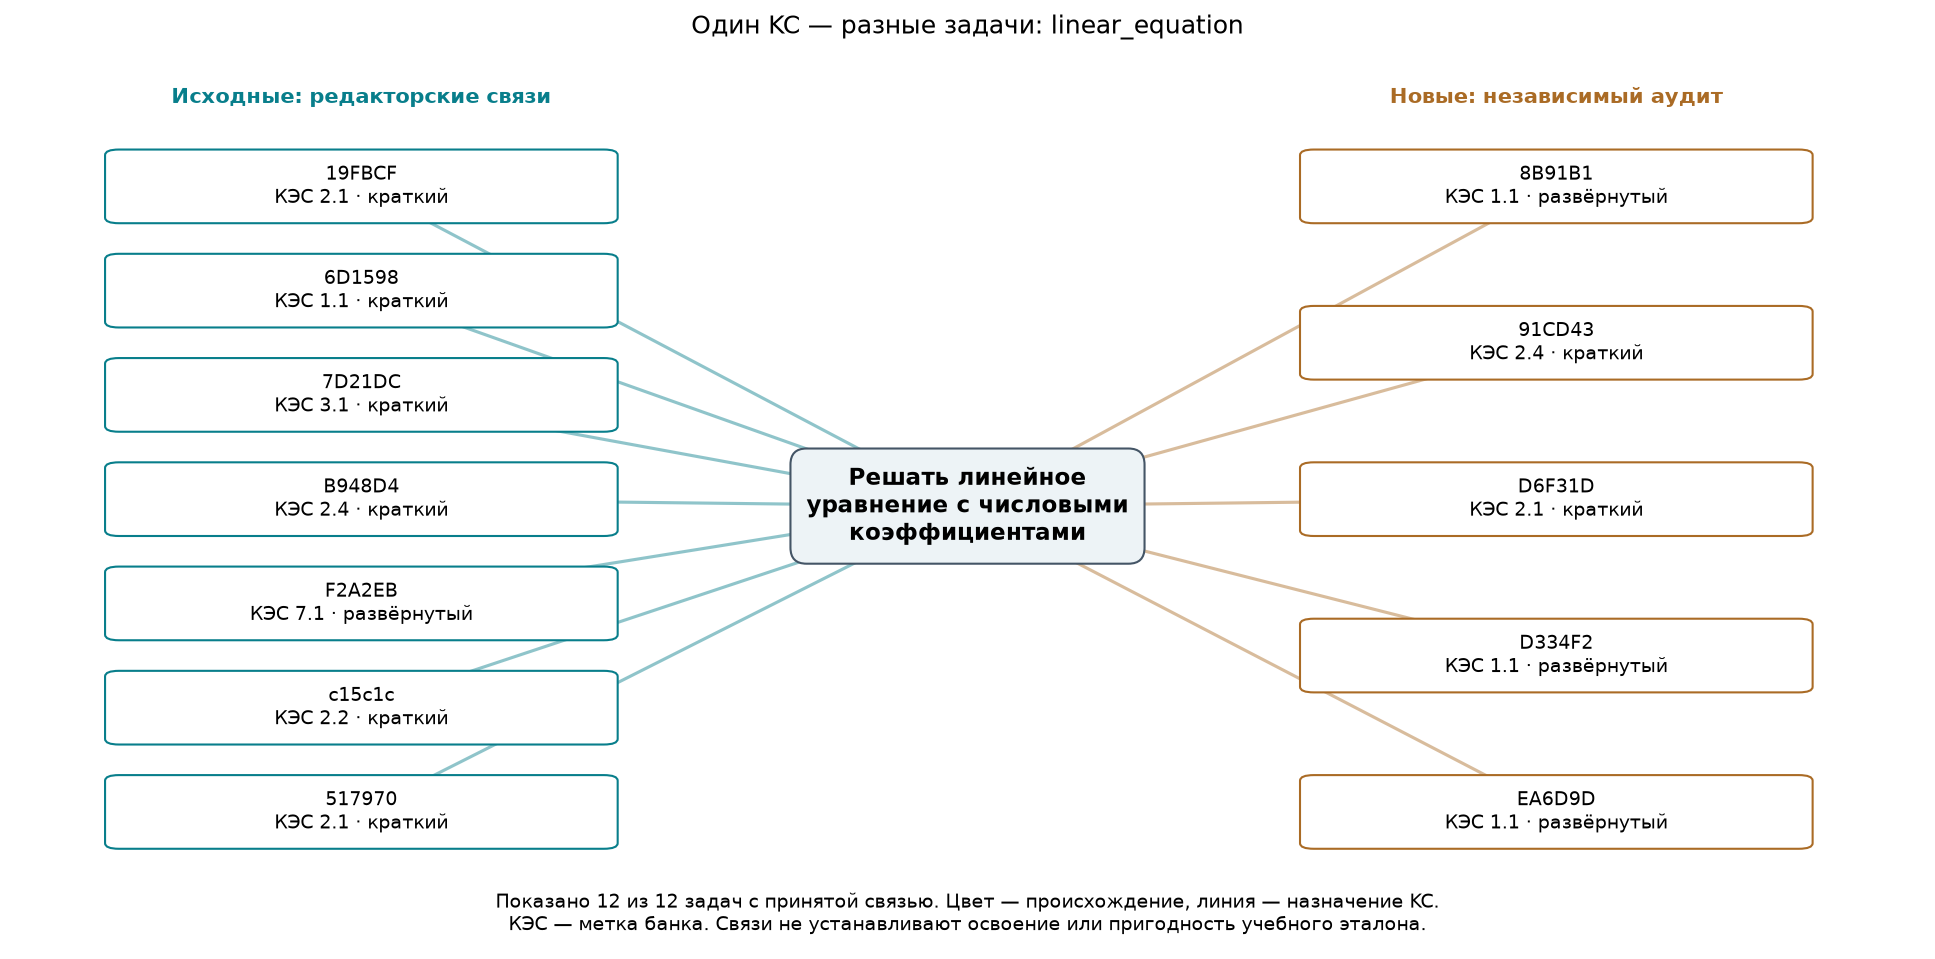

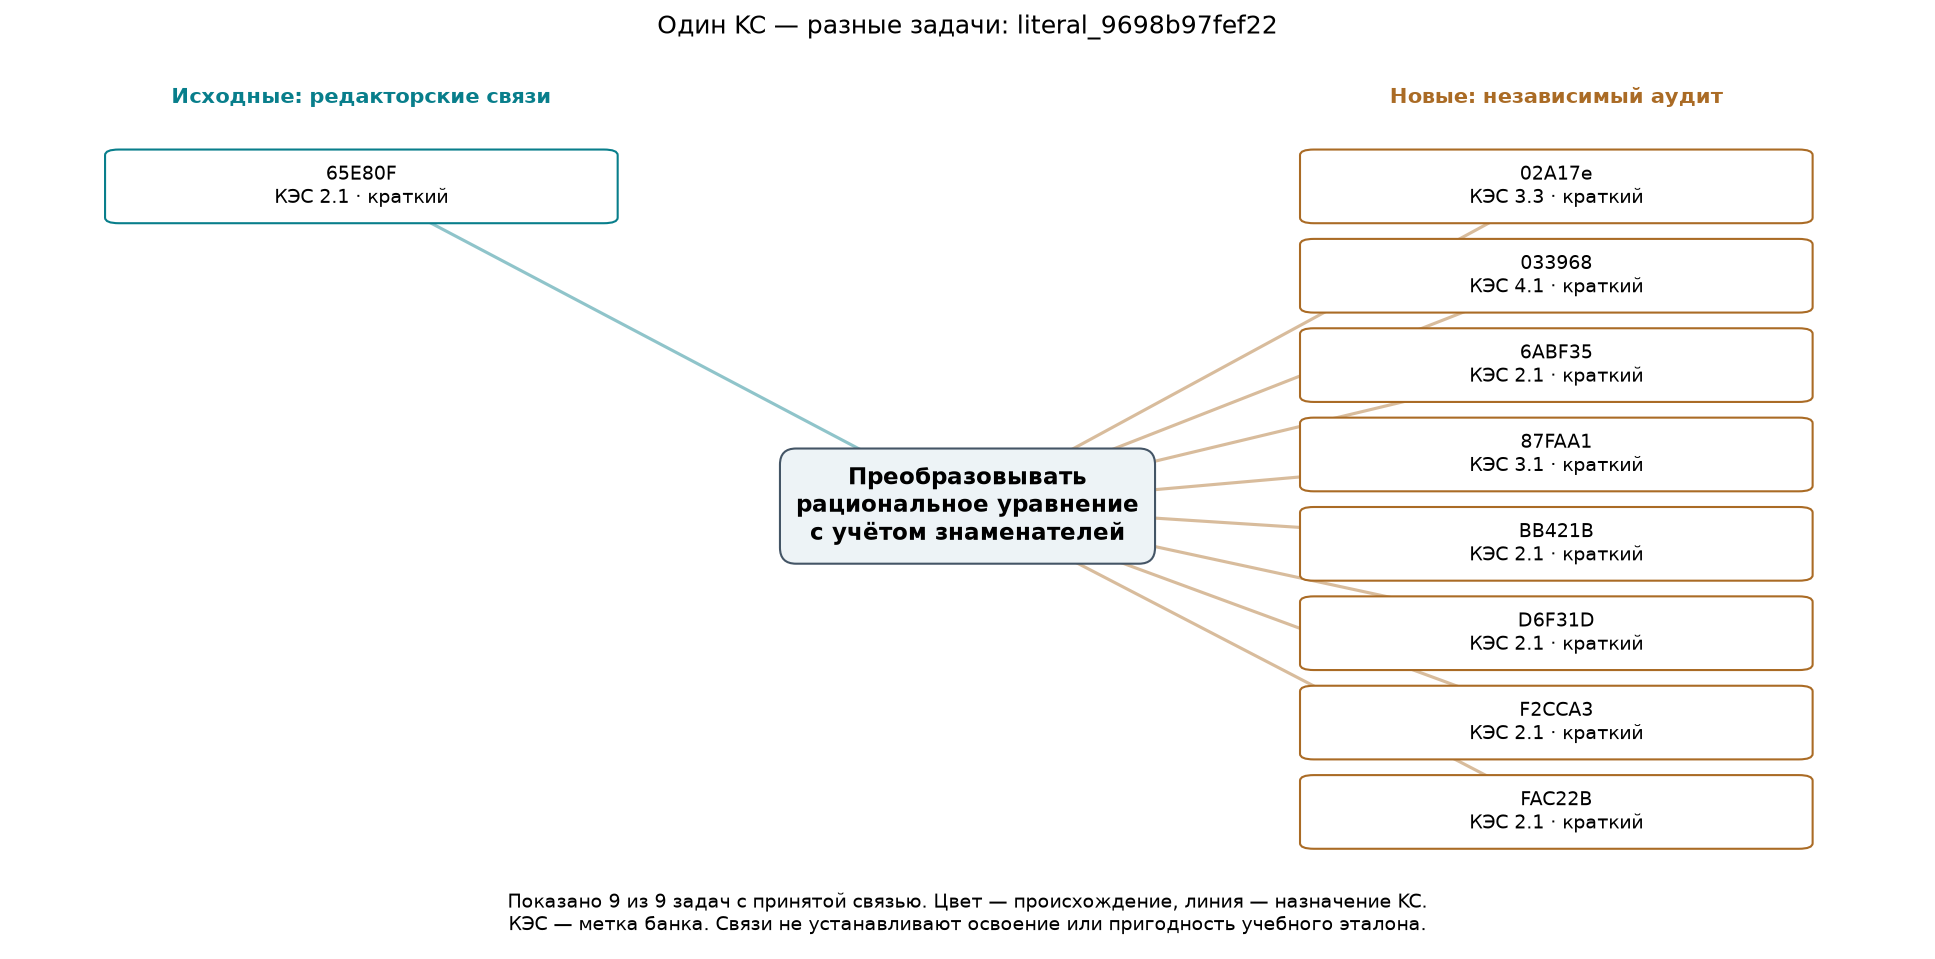

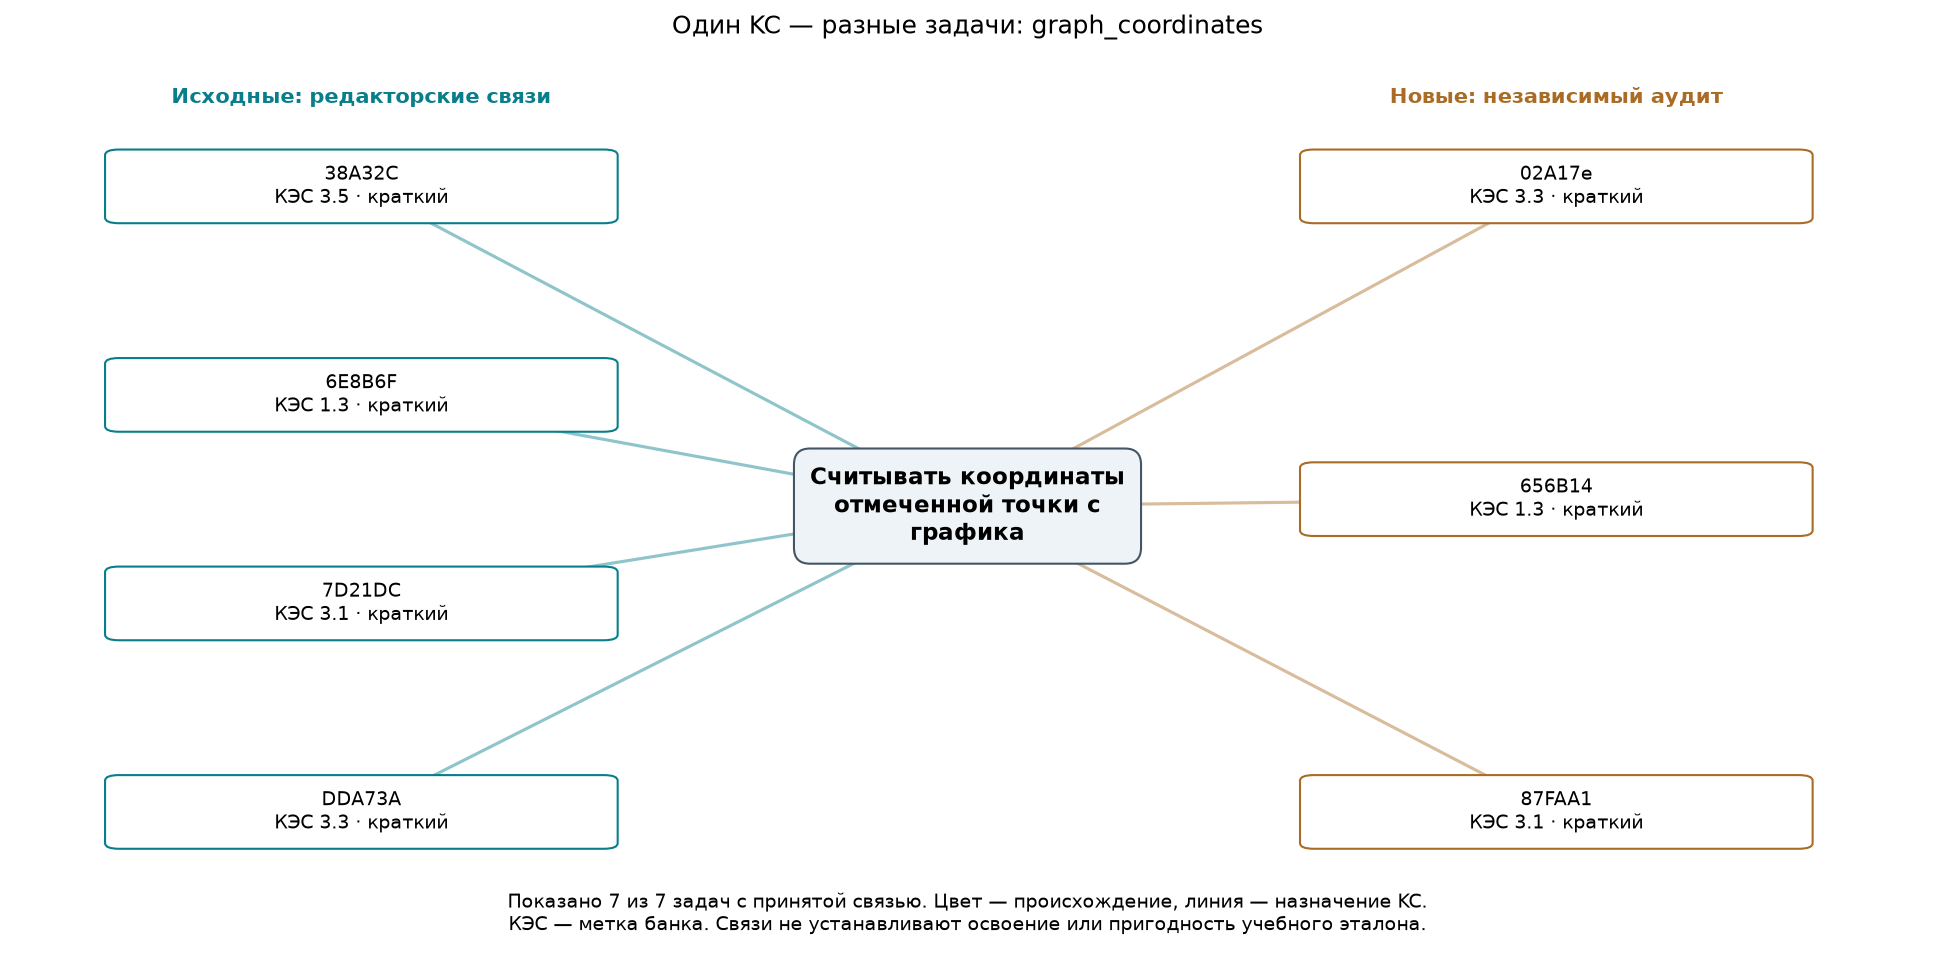

In [2]:
display(Image(filename=str(out / 'figures/graph-linear_equation.png')))
display(Image(filename=str(out / 'figures/graph-literal_9698b97fef22.png')))
display(Image(filename=str(out / 'figures/graph-graph_coordinates.png')))

## 2. Что видно в последовательностях

Показаны четыре цепочки из первого фокуса: 19FBCF (историческая), 8B91B1 (новая), 91CD43 и D334F2 (ещё две новые с неполными назначениями), по заранее записанному порядку ID. Полная таблица шагов и контекста — [chains.csv](tables/chains.csv). Несколько KC в шаге — неупорядоченная группа; разные Method не соединяются.

Среди 12 фокусных задач переход «равенство показателей → линейное уравнение» наблюдается в двух задачах; «равенство аргументов логарифмов → линейное уравнение» — также в двух. Остальные показанные направленные пары имеют по одной задаче. Это конкретные наблюдения, а не устойчивый граф prerequisite. [Все соседние пары с ID](tables/focus-transitions.csv).

Соседний шаг с неполным назначением есть у 3 из 12 фокусных задач: 8B91B1, D334F2, EA6D9D. Здесь учитывается именно соседний шаг, содержащий неназначенного кандидата; неполнота внутри самого фокусного шага отмечается на схемах отдельно. Пропуски не удаляются, рёбра через них не достраиваются.

Особенно показателен 91CD43: в s3 решено 8−x=2 и проверено x<8. Назначение linear_equation принято для kc3, проверка допустимости kc4 остаётся без полного назначения. Схема сохраняет обе операции. В 8B91B1 исходные шаги построения модели остаются неназначенными, даже если позднейшее линейное уравнение сопоставлено.










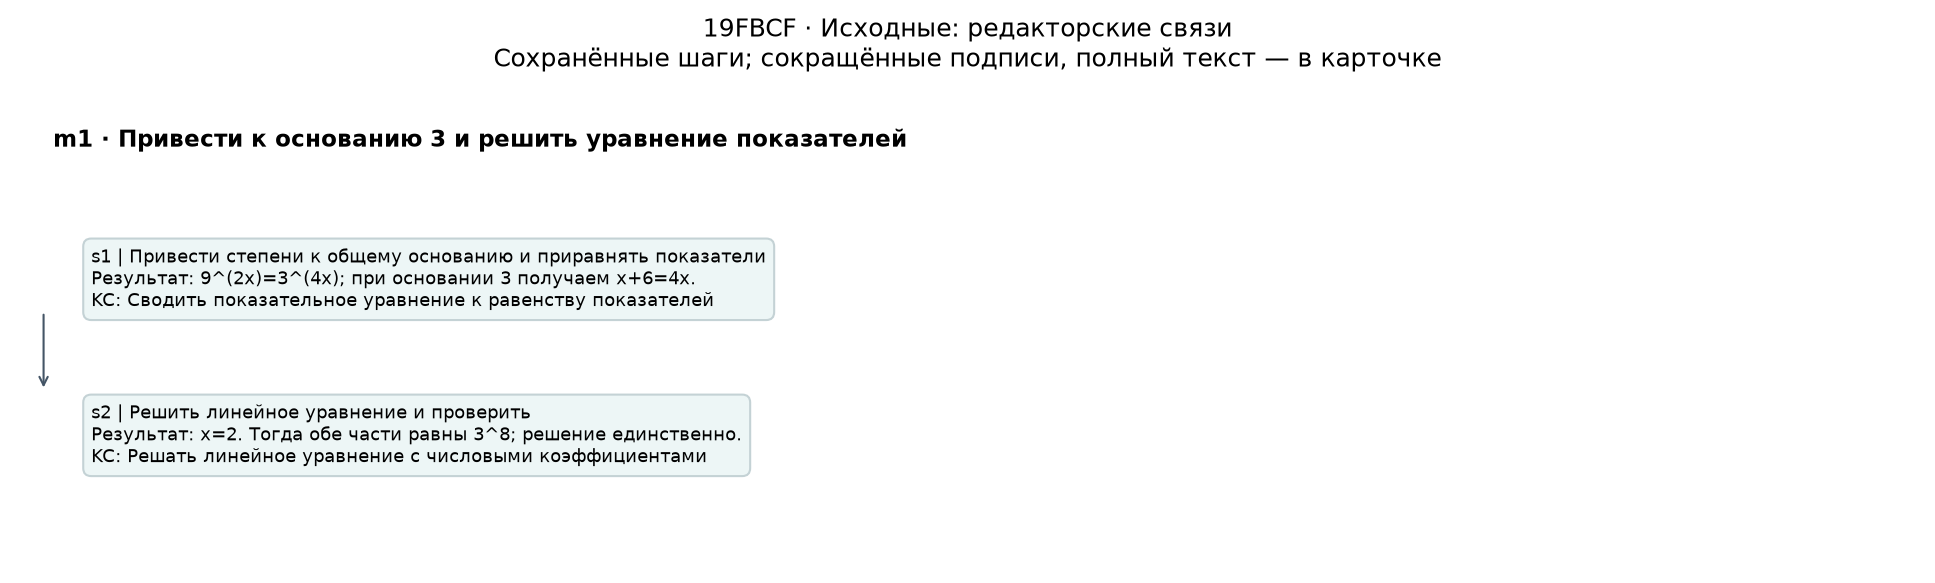

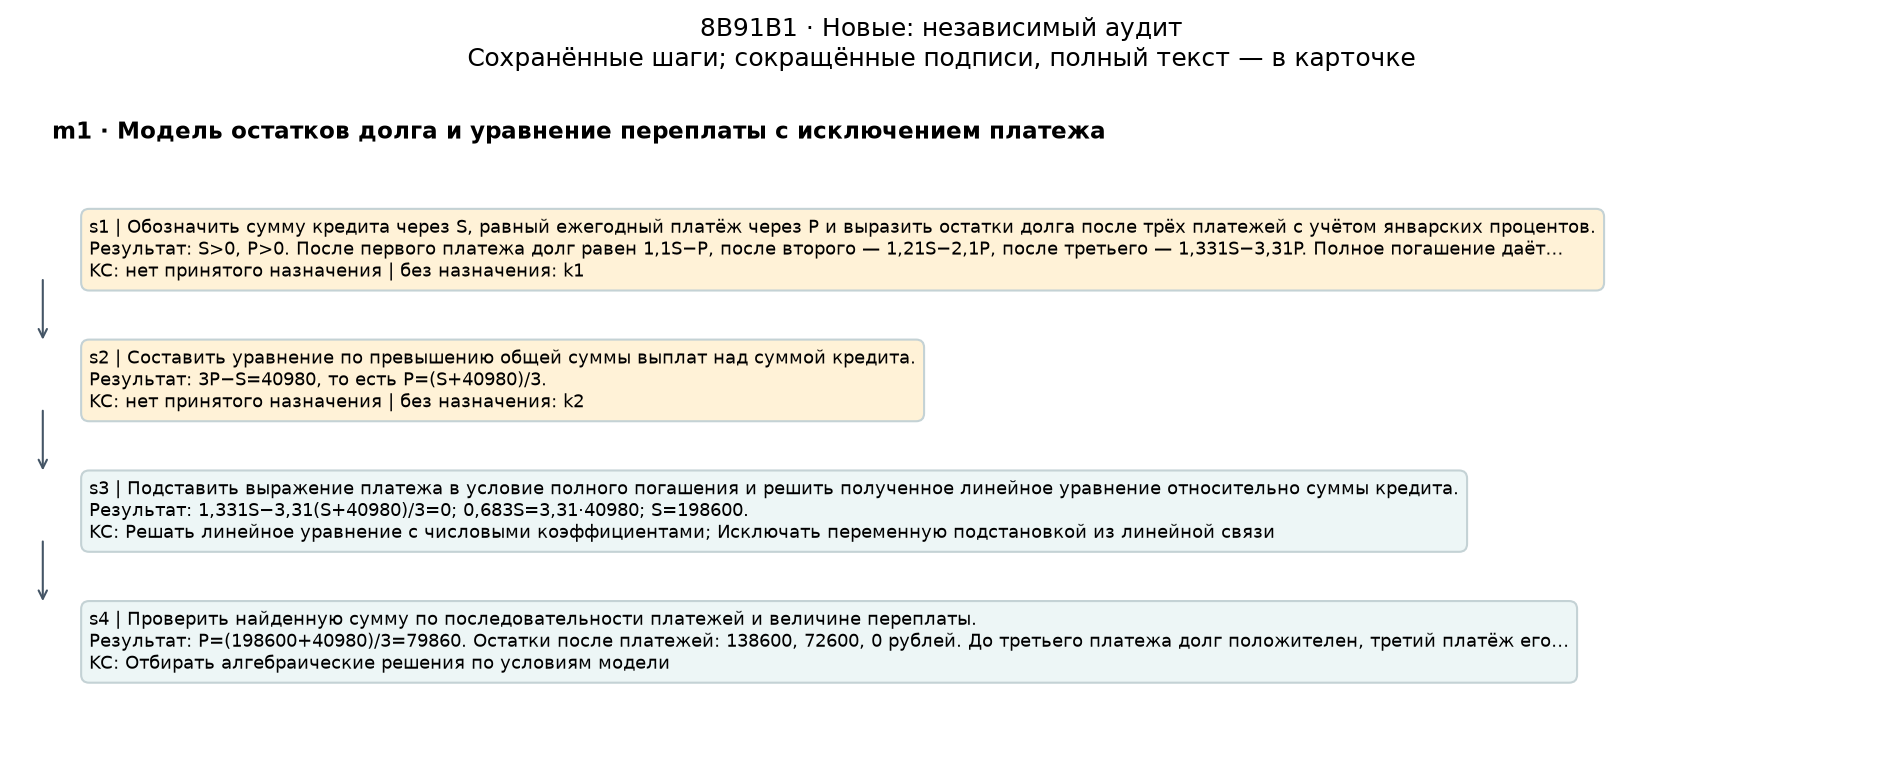

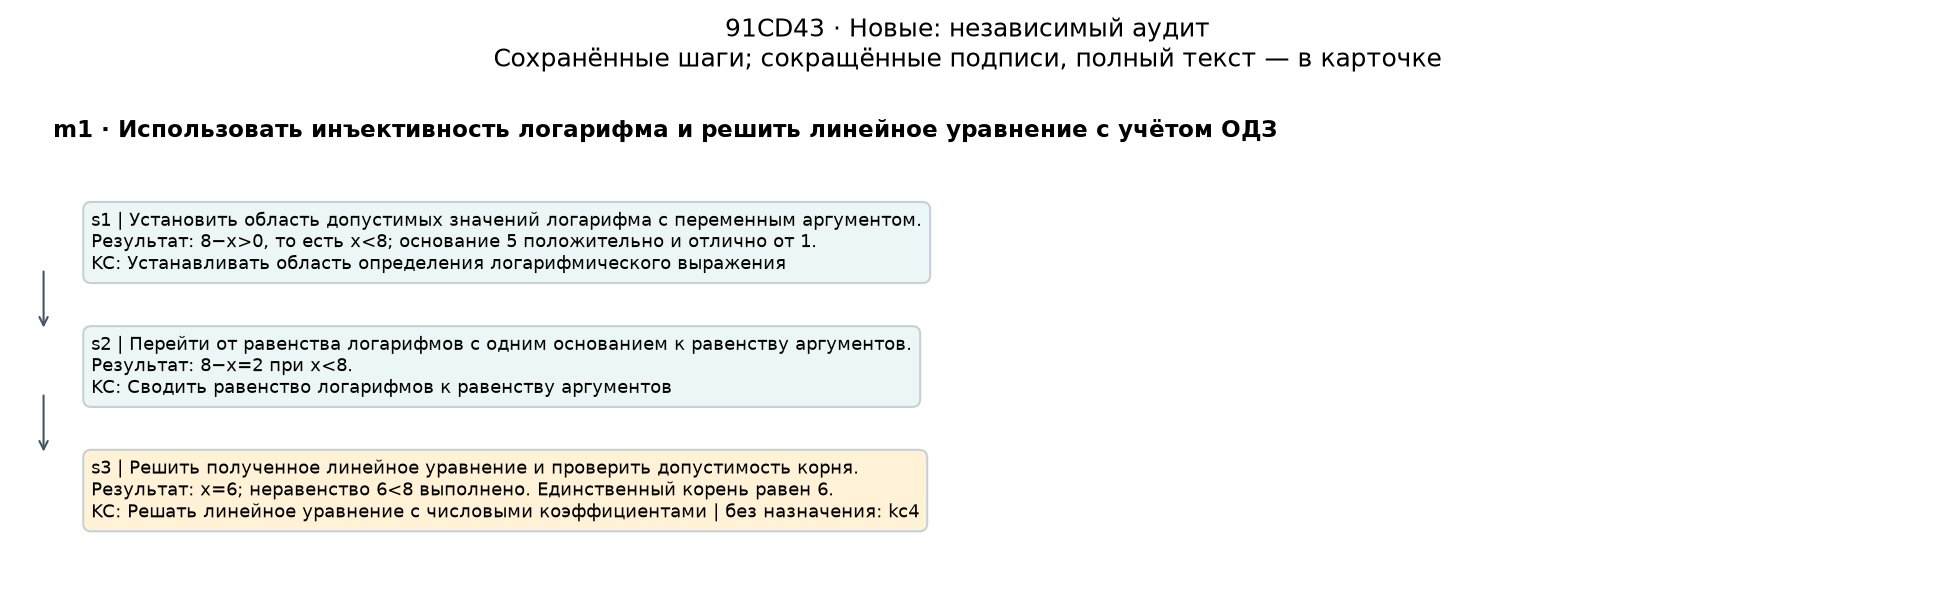

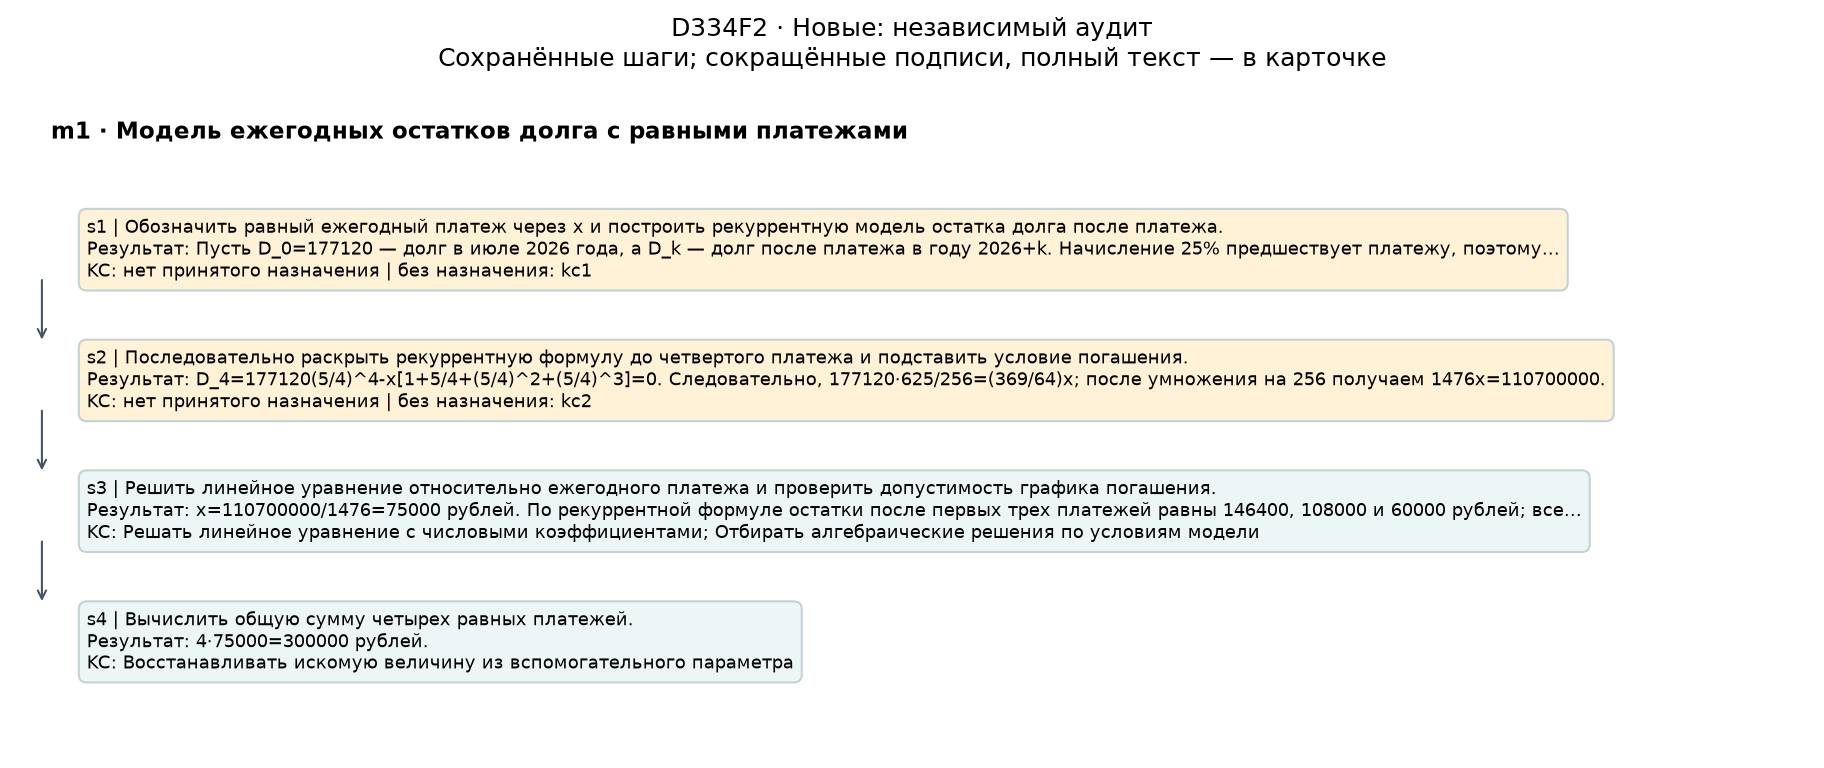

In [3]:
display(Image(filename=str(out / 'figures/chain-19FBCF.png')))
display(Image(filename=str(out / 'figures/chain-8B91B1.png')))
display(Image(filename=str(out / 'figures/chain-91CD43.png')))
display(Image(filename=str(out / 'figures/chain-D334F2.png')))

## 3. Где связи неполны

| Слой включённых задач | Все кандидаты назначены | Часть | Ни одного | Знаменатель |
|---|---:|---:|---:|---:|
| Исторические редакторские связи | 49 | 0 | 0 | 49 |
| Новые независимые аудиты | 4 | 35 | 10 | 49 |



Эта разница **не означает**, что старые решения правильнее. Пилотный каталог построен по исходным кандидатам с редакторскими назначениями; для новых используется замороженный каталог и отдельная процедура. Полнота назначения не проверяет математику и не означает пригодность учебного эталона. В 10 новых включённых задачах ноль принятых назначений, но это не отсутствие математических действий.

Без полного назначения остаются 110/197 кандидатов включённых новых задач; статусы всех новых 50 используют другой знаменатель — 199. [Статусы с отдельными знаменателями](tables/unmatched-statuses.csv), [профиль всех 100 задач и исключения](tables/profiles.csv).

Причины иллюстрируются сохранёнными случаями, а не новой классификацией корпуса:

- [68Ac00](cards/68Ac00.html): составной кандидат соединяет решение уравнения и выбор именованной точки; части не назначаются автоматически.
- [F6158A](cards/F6158A.html): два определения перекрываются на одном действии, однозначный ID не выбран.
- [F416AF](cards/F416AF.html): исправлено чтение изображения с обратной связью, первоначальный автор и аудитор ошибку пропустили. Активная исправленная версия не является независимым повтором.
- [C41083](cards/C41083.html): блокирующий вердикт о предположении независимости; задача исключена из основных частот. Исторический eFF32e также исключён по прежней политике. Эти признаки могут пересекаться с неполными связями, их нельзя складывать в единый процент качества.


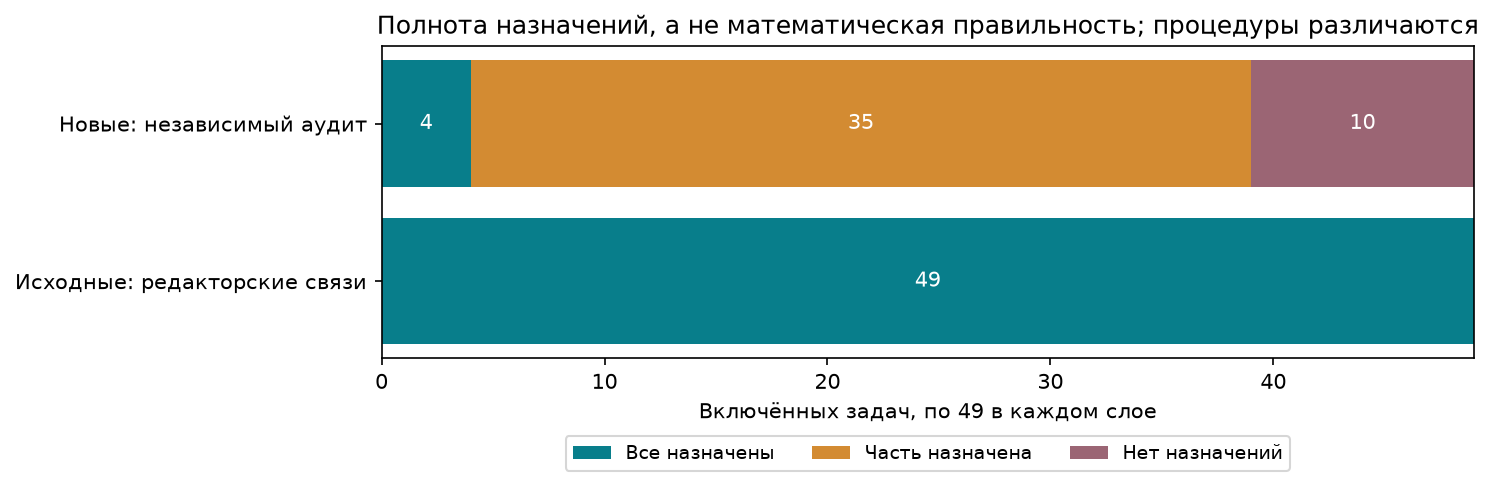

In [4]:
display(Image(filename=str(out / 'figures/mapping-completeness.png')))

## Что это даёт следующему этапу

1. **Для подбора упражнений:** готов список конкретных задач с одним принятым действием, метаданными и основаниями связи. Перед предъявлением ученику нужны предметная проверка решений и согласование границ действия.
2. **Для пошагового представления:** есть наблюдаемые операции и контекст, которые можно сделать явными в интерфейсе. Данные пока не определяют диагностический вопрос, причину ученической ошибки или правило выбора помощи.
3. **Для организации материалов:** видно, где не хватает связей с каталогом и где есть ограничения чтения/допущений. Можно адресно проверять небольшой набор вместо автоматического допуска всех 100 решений.

Не установлены освоение, образовательный эффект, перенос или prerequisite. Следующий шаг — просмотр этих конкретных материалов и отдельное решение о проектировании учебного сценария. Автоматического перехода к прототипу или новой разметке нет.


## Воспроизведение и границы просмотра

Сначала выполнен один фокус, проверены 19FBCF, 8B91B1, 91CD43 и исходное изображение 7D21DC; затем зафиксирован [выборочный просмотр](checks/pilot-visual-review.json) и построены ещё два фокуса. Все восемь картинок просмотрены; HTML проверяется по структуре, ссылкам и сохранности формул/изображений. Полное браузерное отображение HTML не проверялось. Это технический и выборочный просмотр основного ассистента, не независимая математическая экспертиза.

Из корня репозитория:

```powershell
.venv/Scripts/python.exe -B -X utf8 scripts/analyze_data_to_tutor.py --phase complete
.venv/Scripts/python.exe -B -X utf8 scripts/finalize_data_to_tutor.py
```

Первоначальный запуск использовал --phase pilot, затем сохранённую визуальную проверку с хешами кода и графиков. Повторное исполнение complete требует этот журнал и неизменную копию PROTOCOL.md; при изменении кода проверку надо выполнить заново в новой версии результата. Нужны matplotlib, numpy, lxml, Pillow, nbformat, nbclient и ipykernel из существующей .venv; версии сохранены в provenance.json. Ядру Jupyter требуется локальное loopback-соединение, внешней сети и моделей нет.

manifest.json хранит Git SHA начала, полные/показанные ID и правила; provenance.json — входы и хеши; checks/final.json — результаты проверки и replay; output-hashes.json — хеши выходов. Исторические данные, каталоги и предварительный EDA остаются без изменений. Результат локальный, без commit/push.
